# 🔢 Étape 4 : La loi de Benford

**L'idée :** dans beaucoup de données financières réelles, les montants qui commencent par **1** sont bien plus fréquents que ceux qui commencent par **9**. Environ **30 %** contre **4,6 %**. Cette régularité porte le nom de **loi de Benford**.

**Pourquoi c'est utile en audit :** quand quelqu'un **invente** des montants, il a tendance à répartir les chiffres de façon trop uniforme, ou à se concentrer sur certains montants (juste sous un seuil, montants ronds…). Un écart à la loi de Benford ne prouve pas une fraude, mais il **indique où chercher**.

**Différence avec l'étape 3 :** ici, on ne dit pas à l'outil quelle fraude chercher. On compare simplement les données à ce qu'elles « devraient » être.

Plan :
1. La loi de Benford en une formule
2. Test du premier chiffre sur tout le FEC
3. Test des deux premiers chiffres : plus fin, il fait ressortir des pics
4. Benford par fournisseur : trouver le segment anormal
5. Le complément indispensable : les montants ronds
6. Bilan : ce que Benford trouve, et ce qu'il ne trouve pas

> Le code est dans [`src/benford.py`](../src/benford.py).

## 1. La loi de Benford

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

RACINE = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.append(str(RACINE / "src"))
from chargement import charger_fec
import benford as bf
import tests_audit as ta

FIGURES = RACINE / "reports" / "figures"
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 100})
pd.options.display.float_format = lambda x: f"{x:,.4f}".replace(",", " ")

def sauver(fig, nom):
    fig.savefig(FIGURES / f"{nom}.png", dpi=120, bbox_inches="tight")

La probabilité que le premier chiffre soit égal à $d$ vaut :

$$P(d) = \log_{10}\left(1 + \frac{1}{d}\right)$$

In [2]:
bf.distribution_benford(1).to_frame("probabilité").style.format("{:.1%}")

,probabilité
1,30.1%
2,17.6%
3,12.5%
4,9.7%
5,7.9%
6,6.7%
7,5.8%
8,5.1%
9,4.6%


**Quand la loi s'applique-t-elle ?** Quand les montants :
- s'étalent sur **plusieurs ordres de grandeur** (de 10 € à 100 000 €, par exemple) ;
- résultent de **multiplications naturelles** (prix × quantités, TVA…) ;
- ne sont **pas fixés à l'avance** : un loyer de 3 500 € tous les mois ne suit pas Benford, et c'est normal.

À l'étape 2, on a vu que nos montants s'étalent sur 4 ordres de grandeur : les conditions sont réunies.

## 2. Test du premier chiffre sur tout le FEC

On analyse tous les montants des lignes d'écritures (hors à-nouveaux) d'au moins 10 €.

Trois indicateurs :
- **MAD** (*Mean Absolute Deviation*) : l'écart moyen entre la répartition observée et la théorique. C'est l'indicateur de référence en audit, avec les **seuils de Nigrini** ;
- **Khi-deux** : un test statistique classique, avec sa p-value ;
- **Test z** par chiffre : un chiffre est significativement anormal si z > 1,96.

In [3]:
fec = charger_fec()
fec = fec[fec["JournalCode"] != "AN"]
montants = fec["Debit"] + fec["Credit"]

premier = bf.test_benford(montants, n=1)
premier.resume().to_frame("résultat")

,résultat
Montants analysés,16 949
MAD (écart absolu moyen),0.0022
Verdict (seuils de Nigrini),Conformité forte
Khi-deux,12.1
p-value,0.147


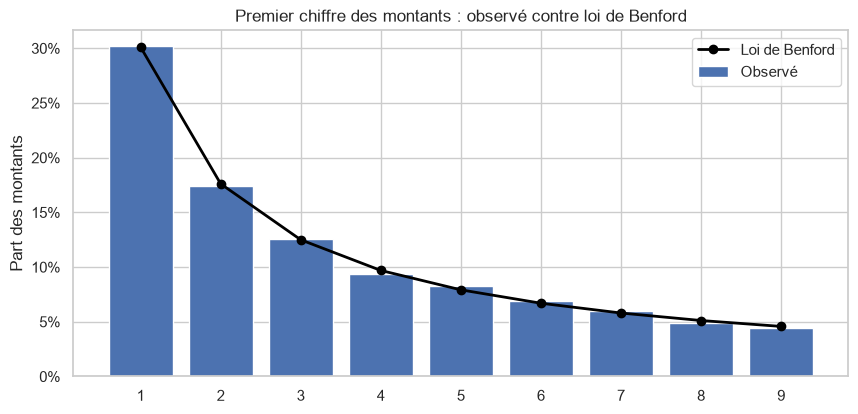

,effectif,observé,attendu,écart,z
chiffre,,,,,
1,5113,30.2%,30.1%,+0.06%,0.17
2,2948,17.4%,17.6%,-0.22%,0.73
3,2135,12.6%,12.5%,+0.10%,0.39
4,1582,9.3%,9.7%,-0.36%,1.56
5,1405,8.3%,7.9%,+0.37%,1.78
6,1177,6.9%,6.7%,+0.25%,1.29
7,1020,6.0%,5.8%,+0.22%,1.20
8,825,4.9%,5.1%,-0.25%,1.45
9,744,4.4%,4.6%,-0.19%,1.14


In [4]:
def graphique_benford(resultat, titre, nom_figure, seuil_z=1.96, largeur=(10, 4.5)):
    t = resultat.tableau
    fig, ax = plt.subplots(figsize=largeur)
    couleurs = np.where(t["z"] > seuil_z, "#C44E52", "#4C72B0")
    ax.bar(t.index.astype(str), t["observé"], color=couleurs, label="Observé")
    ax.plot(t.index.astype(str), t["attendu"], color="black", marker="o" if len(t) < 20 else None,
            linewidth=2, label="Loi de Benford")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
    if len(t) > 20:
        ax.set_xticks(range(0, len(t), 5))
    ax.set(title=titre, ylabel="Part des montants")
    ax.legend()
    sauver(fig, nom_figure)
    plt.show()

graphique_benford(premier, "Premier chiffre des montants : observé contre loi de Benford", "09_benford_premier_chiffre")
premier.tableau.style.format({"observé": "{:.1%}", "attendu": "{:.1%}", "écart": "{:+.2%}", "z": "{:.2f}"})

👉 Les montants suivent **très bien** la loi de Benford : MAD faible, conformité forte selon Nigrini, aucun chiffre significativement anormal. **À l'échelle globale, rien de suspect.**

C'est un enseignement important : **81 anomalies sur près de 17 000 montants, c'est trop peu pour déformer la distribution globale.** Il faut regarder plus finement.

## 3. Test des deux premiers chiffres

Au lieu de 9 catégories (1 à 9), on en utilise 90 (10 à 99). Le test est beaucoup plus **précis** : il peut faire ressortir un montant particulier, utilisé de façon anormale.

In [5]:
deux = bf.test_benford(montants, n=2)
deux.resume().to_frame("résultat")

,résultat
Montants analysés,16 949
MAD (écart absolu moyen),0.0009
Verdict (seuils de Nigrini),Conformité forte
Khi-deux,165.6
p-value,1.53e-06


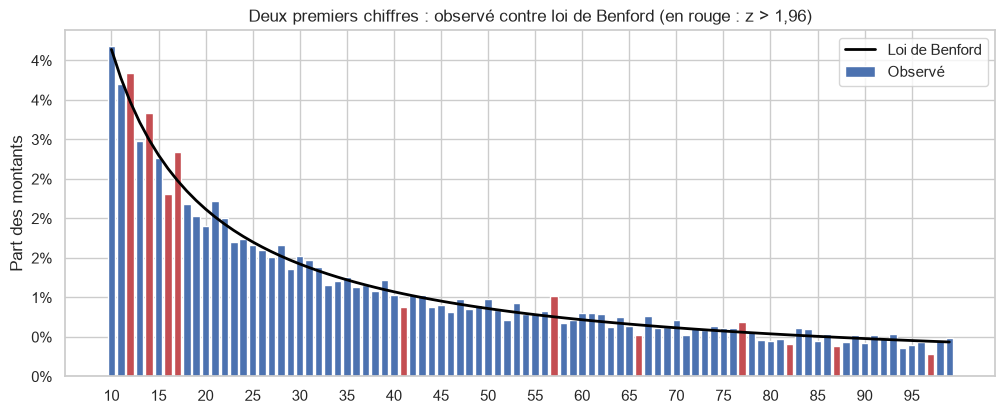

In [6]:
graphique_benford(deux, "Deux premiers chiffres : observé contre loi de Benford (en rouge : z > 1,96)",
                  "10_benford_deux_chiffres", largeur=(12, 4.5))

**Attention au piège statistique :** le MAD indique une conformité forte, mais la p-value du khi-deux est très faible. Qui croire ?

- Avec près de 17 000 montants, le khi-deux devient **hypersensible** : le moindre écart devient « significatif ». C'est pour cela que les auditeurs préfèrent le **MAD**, qui ne dépend pas de la taille de l'échantillon.
- Avec 90 tests z à 5 %, on s'attend à environ **4 à 5 pics « significatifs » par pur hasard**. Il faut donc regarder **les pics les plus marqués**, pas tous les pics rouges.

In [7]:
pics = deux.tableau[deux.tableau["écart"] > 0].sort_values("z", ascending=False).head(5)
pics.style.format({"observé": "{:.2%}", "attendu": "{:.2%}", "écart": "{:+.2%}", "z": "{:.2f}"})

,effectif,observé,attendu,écart,z
deux premiers chiffres,,,,,
57,172,1.01%,0.76%,+0.26%,3.86
17,481,2.84%,2.48%,+0.36%,2.95
12,651,3.84%,3.48%,+0.36%,2.57
14,565,3.33%,3.00%,+0.34%,2.55
77,116,0.68%,0.56%,+0.12%,2.11


Le pic le plus marqué concerne les montants commençant par **57**. Allons voir quelles écritures se cachent derrière.

In [8]:
chiffres = bf.premiers_chiffres(montants, n=2)
lignes_57 = fec.loc[chiffres[chiffres == 57].index]

# Pour chaque écriture, on récupère son tiers (client ou fournisseur)
ecr = ta.tableau_ecritures(fec)
lignes_57 = lignes_57.assign(tiers=lignes_57["EcritureNum"].map(ecr["tiers_lib"]))

attendu_57 = deux.tableau.loc[57, "attendu"] * deux.effectif
print(f"Montants commençant par 57 : {len(lignes_57)} observés pour {attendu_57:.0f} attendus "
      f"(excédent de {len(lignes_57) - attendu_57:.0f})")

Montants commençant par 57 : 172 observés pour 128 attendus (excédent de 44)


Un gros client apparaît naturellement souvent, simplement parce qu'il a beaucoup d'écritures. Pour chaque tiers, on compare donc le nombre de montants commençant par 57 à **ce que Benford prévoit compte tenu de son volume**.

In [9]:
fec_tiers = fec.assign(tiers=fec["EcritureNum"].map(ecr["tiers_lib"]))
volume = fec_tiers.loc[chiffres.index, "tiers"].value_counts()
contribution = pd.DataFrame({
    "montants commençant par 57": lignes_57["tiers"].value_counts(),
    "montants du tiers (total)": volume,
}).dropna()
contribution = contribution[contribution.index != ""]
contribution["attendus par Benford"] = contribution["montants du tiers (total)"] * deux.tableau.loc[57, "attendu"]
contribution["ratio observé / attendu"] = (contribution["montants commençant par 57"]
                                           / contribution["attendus par Benford"])
contribution.sort_values("montants commençant par 57", ascending=False).head(6).style.format(
    {"montants commençant par 57": "{:.0f}", "montants du tiers (total)": "{:.0f}",
     "attendus par Benford": "{:.1f}", "ratio observé / attendu": "× {:.1f}"})

,montants commençant par 57,montants du tiers (total),attendus par Benford,ratio observé / attendu
tiers,,,,
Conseil Stratégie Plus,21,70,0.5,× 39.7
Galerie Garonne,15,1806,13.6,× 1.1
Boutique Montmartre,12,1043,7.9,× 1.5
Studio Bellevue,11,542,4.1,× 2.7
Distribution Nordlicht,11,226,1.7,× 6.4
Agence du Port,8,445,3.4,× 2.4


👉 **Un tiers sort complètement du lot : « Conseil Stratégie Plus ».** Il représente à lui seul environ la moitié de l'excédent de « 57 », avec un ratio de plusieurs dizaines de fois ce qui est attendu. Les autres tiers ont des ratios bien plus modestes (entre 1 et 6 environ), compatibles avec le hasard sur de petits effectifs : quelques montants de plus ou de moins suffisent à faire varier le ratio.

Ses factures TTC (entre 5 700 et 6 000 €) et leurs règlements commencent tous par 57, 58 ou 59. C'est le fournisseur fictif qui facture juste sous le seuil de 5 000 € HT : Benford l'a fait ressortir **sans qu'on lui dise quoi chercher**.

## 4. Benford par fournisseur

L'analyse globale dilue les anomalies. L'auditeur **segmente** donc les données : par fournisseur, par compte, par utilisateur… On applique ici le test du premier chiffre aux montants HT facturés par chaque fournisseur ayant au moins 10 factures.

In [10]:
achats_ht = fec[(fec["JournalCode"] == "AC") & fec["CompteNum"].str.startswith("6") & (fec["Debit"] > 0)]
achats_ht = achats_ht.assign(fournisseur=achats_ht["EcritureNum"].map(ecr["tiers_lib"]))

par_fournisseur = bf.benford_par_groupe(achats_ht, "fournisseur", "Debit", effectif_min=10)
par_fournisseur.head(8).style.format({"MAD": "{:.3f}", "p-value": "{:.2g}",
                                      "part du chiffre dominant": "{:.0%}", "attendu pour ce chiffre": "{:.0%}"})

,montants,MAD,p-value,chiffre dominant,part du chiffre dominant,attendu pour ce chiffre
fournisseur,,,,,,
Conseil Stratégie Plus,14,0.201,2.3e-24,4,100%,10%
SCI Les Tilleuls,12,0.194,7.5e-15,3,100%,12%
Distribution Nordlicht,46,0.061,0.017,2,24%,18%
TéléCom Pro Services,12,0.118,0.025,1,83%,30%
Manufacture Céramique du Sud,59,0.048,0.037,2,24%,18%
Grossiste Nordlicht,46,0.041,0.13,1,30%,30%
Comptoir Atlas,45,0.035,0.16,1,31%,30%
Comptoir Métal Design,62,0.038,0.16,1,40%,30%


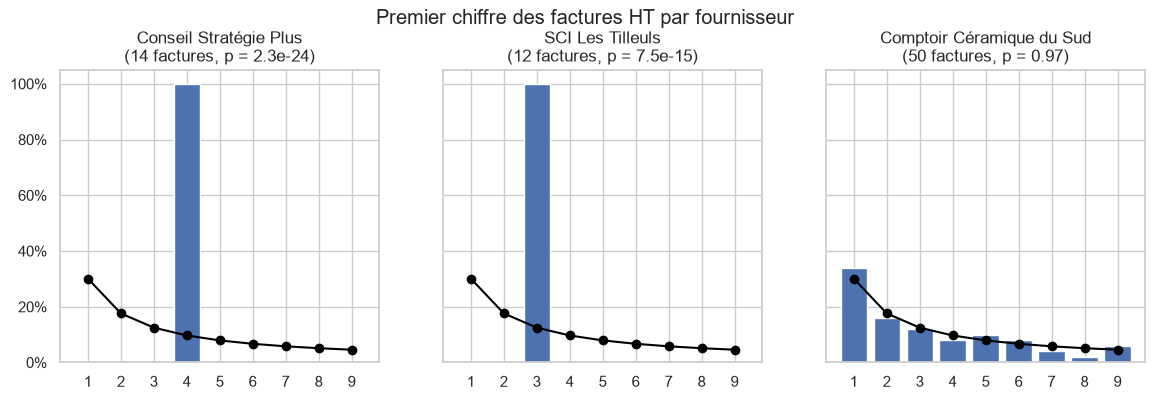

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
exemples = ["Conseil Stratégie Plus", "SCI Les Tilleuls", par_fournisseur.index[-1]]
for ax, nom in zip(axes, exemples):
    r = bf.test_benford(achats_ht.loc[achats_ht["fournisseur"] == nom, "Debit"])
    ax.bar(r.tableau.index.astype(str), r.tableau["observé"], color="#4C72B0")
    ax.plot(r.tableau.index.astype(str), r.tableau["attendu"], color="black", marker="o")
    ax.set(title=f"{nom}\n({r.effectif} factures, p = {r.p_value:.2g})")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
fig.suptitle("Premier chiffre des factures HT par fournisseur", y=1.04)
sauver(fig, "11_benford_par_fournisseur")
plt.show()

Trois profils très différents :

1. **Conseil Stratégie Plus** : 100 % des factures commencent par **4** (entre 4 750 et 4 990 € HT), contre 9,7 % attendus. Aucun fournisseur réel ne facture ainsi : c'est le **fractionnement sous le seuil d'approbation**.
2. **SCI Les Tilleuls** : 100 % des factures commencent par 3, mais c'est **un loyer fixe** de 3 500 € HT. Benford ne s'applique pas aux montants fixés à l'avance : c'est une **fausse alerte**, écartée en 30 secondes.
3. **Un fournisseur ordinaire** : les montants suivent la courbe de Benford, aux variations près dues au petit nombre de factures.

👉 **La leçon d'audit :** Benford **oriente** l'analyse, mais c'est le **jugement professionnel** qui conclut. Un écart s'explique soit par la nature de l'activité (loyer, abonnement), soit par une anomalie.

> ⚠️ Avec peu de factures (10 à 60 par fournisseur), les tests statistiques sont fragiles. On s'intéresse donc aux écarts **extrêmes**, pas aux petites différences.

## 5. Le complément indispensable : les montants ronds

Benford porte sur les **premiers** chiffres. Les fraudeurs laissent aussi des traces dans les **derniers** chiffres : un montant inventé est souvent **rond** (sans centimes, multiple de 100 €). Dans des données naturelles, environ 1 % des montants n'ont pas de centimes, et 0,01 % sont des multiples de 100 €.

In [12]:
ronds = (fec.assign(montant=montants)
         .groupby(["JournalCode", "JournalLib"])["montant"]
         .apply(bf.part_montants_ronds).unstack())
ronds["montants"] = ronds["montants"].astype(int)
ronds.style.format({"sans centimes": "{:.1%}", "multiples de 100 €": "{:.1%}"})

,,montants,sans centimes,multiples de 100 €
JournalCode,JournalLib,,,
AC,Journal des achats,3625,2.2%,1.2%
BQ,Banque,6016,2.7%,0.8%
OD,Opérations diverses,34,100.0%,76.5%
PA,Paie,60,100.0%,1.7%
VE,Journal des ventes,7214,1.6%,0.2%


- **Paie** : 100 % de montants sans centimes, ce qui est normal, car les salaires bruts de la simulation sont arrondis à la dizaine.
- **Opérations diverses** : environ **3 montants sur 4 sont des multiples de 100 €**. C'est un journal de saisie manuelle, qui concentre ici les sorties de banque rondes au libellé vague (« Divers », « Ajustement »…).
- **Ventes** : la part de multiples de 100 € est faible, mais pas nulle. On y trouve les ventes fictives de fin d'année, aux montants HT ronds.

👉 Le journal des **OD** mérite donc une revue détaillée. C'est d'ailleurs le journal le plus surveillé en audit, car les écritures y sont saisies manuellement, sans pièce automatique.

## 6. Bilan : ce que Benford trouve, et ce qu'il ne trouve pas

On compare avec la « correction » : quels types d'anomalies cette approche a-t-elle mis en évidence ?

In [13]:
anomalies = pd.read_csv(RACINE / "data" / "raw" / "anomalies_injectees.csv")
bilan = pd.DataFrame({
    "type d'anomalie": ["fractionnement_seuil", "montant_rond", "vente_fictive_cloture", "doublon",
                        "saisie_weekend", "validation_tardive", "contrepartie_inhabituelle", "desequilibre"],
    "mis en évidence par Benford ?": ["✅ Oui : pic « 57 » et analyse par fournisseur",
                                      "✅ Oui : test des montants ronds (journal OD)",
                                      "🟡 Partiellement : multiples de 100 € dans les ventes",
                                      "❌ Non : un doublon reprend un montant normal",
                                      "❌ Non : la date ne change pas le montant",
                                      "❌ Non : idem",
                                      "❌ Non : c'est le schéma comptable qui est anormal",
                                      "❌ Non : erreur de saisie isolée"],
})
bilan["nombre"] = bilan["type d'anomalie"].map(anomalies["type_anomalie"].value_counts())
bilan.set_index("type d'anomalie")

,mis en évidence par Benford ?,nombre
type d'anomalie,,
fractionnement_seuil,✅ Oui : pic « 57 » et analyse par fournisseur,14
montant_rond,✅ Oui : test des montants ronds (journal OD),12
vente_fictive_cloture,🟡 Partiellement : multiples de 100 € dans les ...,10
doublon,❌ Non : un doublon reprend un montant normal,12
saisie_weekend,❌ Non : la date ne change pas le montant,15
validation_tardive,❌ Non : idem,8
contrepartie_inhabituelle,❌ Non : c'est le schéma comptable qui est anormal,6
desequilibre,❌ Non : erreur de saisie isolée,4


## ✅ Ce qu'il faut retenir

| | |
|---|---|
| **Forces** | Aucune hypothèse sur la fraude ; rapide sur des millions de lignes ; repère les montants **inventés** ou **répétitifs** (fournisseur fictif, montants ronds) |
| **Limites** | Ne détecte rien à l'échelle globale si les anomalies sont rares ; inopérant sur les montants fixes ; aveugle aux anomalies de **date**, de **schéma** ou de **doublon** |
| **Bonne pratique** | Segmenter (par fournisseur, compte, journal, utilisateur) et toujours confronter les écarts au contexte de l'activité |

**Benford et les tests d'audit sont complémentaires.** L'étape 5 franchit un cap : un algorithme de **machine learning non supervisé** va combiner toutes ces dimensions (montant, date, délai de validation, schéma comptable…) pour attribuer à chaque écriture un **score d'anomalie**, sans connaître la correction.